# XGBoost Cross-Condition Robustness — Sinhala Hate Speech Detection

**Experiment design:** train one XGBoost model per condition (clean, transliteration, codemix,
all_noise, misspell, compound — each using only **heavy** severity where noise applies), then test
**every trained model against every condition's test set**. This produces a 6x6 matrix: for each
(train condition, test condition) pair, how well does a model trained on one kind of text
generalize to another?

The diagonal of this matrix (train=test) reproduces the same kind of "own-condition" result from
the earlier notebooks. The off-diagonal cells are new: they tell you whether, say, a model trained
only on clean text collapses when tested on transliterated text, or whether a model trained on
noisy text is actually more robust across the board.

**To add a new condition later: edit only the `CONDITIONS`
dictionary in Section 3** — add one entry with its train/test paths and which text column to read.
Nothing else in the notebook needs to change; every section below loops over `CONDITIONS`
generically.

**Feature representation, training, and evaluation methodology are unchanged from the earlier
notebooks:** character n-gram (1-5) + word n-gram (1-2) TF-IDF (Section 5.3.1 of the proposal),
`scale_pos_weight` for class imbalance, leakage-safe `Pipeline`-based cross-validation (TF-IDF
refit per fold), `RandomizedSearchCV` tuning, macro-F1 as the primary metric.


## How to run this in Colab

1. **Upload your `data.zip`** (the one containing `sold/` and `outputs/`) to your Google Drive —
   anywhere is fine, e.g. `MyDrive/data.zip`.
2. Run **Section 1** below to mount Drive and unzip it into the Colab runtime's local disk (much
   faster to read from than unzipping into Drive itself, and doesn't touch your Drive contents).
3. Check **Section 3**'s `CONDITIONS` dictionary matches your actual folder/file layout (it's
   already set up to match the structure you described:
   `sold/train.jsonl`, `sold/test.jsonl`,
   `outputs/train/{condition}_heavy.jsonl`, `outputs/test/{condition}_heavy.jsonl`
   for each of: `transliteration`, `codemix`, `all_noise`, `misspell`, `compound`).
4. Run every cell top to bottom.


## 1. Setup — install packages, mount Drive, unzip data

In [1]:
!pip install -q --upgrade xgboost scikit-learn scipy joblib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 105.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 63.6 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

# >>> EDIT THIS to the path of your data.zip in Drive <<<
ZIP_PATH = "/content/drive/MyDrive/data.zip"

# Unzipped locally in the Colab runtime (fast disk, not synced to Drive) -- gets wiped when the
# runtime resets, so re-run this cell after every fresh Colab session.
LOCAL_DATA_DIR = "/content/data"

if not os.path.exists(LOCAL_DATA_DIR):
    os.makedirs(LOCAL_DATA_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(LOCAL_DATA_DIR)
    print(f"Unzipped {ZIP_PATH} -> {LOCAL_DATA_DIR}")
else:
    print(f"{LOCAL_DATA_DIR} already exists, skipping re-extraction "
          f"(delete it and re-run this cell if you updated the zip).")

# Sanity check: show what's actually inside after unzipping
for root, dirs, files in os.walk(LOCAL_DATA_DIR):
    level = root.replace(LOCAL_DATA_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files:
        print(f"{indent}  {f}")


Mounted at /content/drive
Unzipped /content/drive/MyDrive/data.zip -> /content/data
data/
  PROVENANCE.json
  demo/
    demo_paragraphs.json
  gold/
    gold_sentences.jsonl
    gold_words.jsonl
    heldout_words.txt
    uom_live_bakeoff.jsonl
    uom_endpoint_verification.jsonl
  sold/
    test.jsonl
    train.jsonl
  lexicon/
    codemix_usage_review.md
    codemix_cmi_reference.json
    codemix_round6_corrections_raw.txt
    codemix_phrase_worklist.jsonl
    .codemix_phrasebank.sha256
    codemix_translation_worklist.jsonl
    codemix_phrase_review_corrections.jsonl
    codemix_translation_rejects.jsonl
    codemix_rejected_candidates.md
    codemix_usage_review.csv
    codemix_reference_stats.json
    codemix_translation_results.jsonl
    .codemix_wordbank.sha256
    .codemix_batch_id.txt
    codemix_cmi_bands.json
    .codemix_cmi_bands.sha256
    codemix_lexicon.jsonl
    .codemix_cmi_reference.sha256
    codemix_round6_corrections.csv
    codemix_wordbank.jsonl
    codemix_candi

## 2. Where results get saved

All trained models, the results matrix, plots, and analysis outputs are saved under
`/content/drive/MyDrive/data/results/xgboost_crosscondition/` (in your actual Drive, not the local
unzip) so they persist after the Colab runtime resets.


In [3]:
RESULTS_DIR = "/content/drive/MyDrive/data/results/xgboost_crosscondition"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Results will be saved to:", RESULTS_DIR)


Results will be saved to: /content/drive/MyDrive/data/results/xgboost_crosscondition


## 3. Configure conditions — the one place to edit for new datasets

Each entry: `train`/`test` are paths under `LOCAL_DATA_DIR`, and `text_columns` is a priority list
of column names to check for the actual text to feed the model (checked in order; first match
wins). This matters because noisy files often contain **both** `original_text` and `noisy_text` —
for a noise condition you want `noisy_text`, for the clean condition you want `original_text`/
`text`, so each condition specifies its own priority list rather than sharing one.

**Only `"heavy"` severity is used here**, per your instruction — the noisy file paths point
directly at the `_heavy.jsonl` files, not `_light.jsonl`.


In [4]:
CONDITIONS = {
    "clean": {
        "train": os.path.join(LOCAL_DATA_DIR, "sold", "train.jsonl"),
        "test":  os.path.join(LOCAL_DATA_DIR, "sold", "test.jsonl"),
        "text_columns": ["original_text", "text", "clean_text"],
    },
    "transliteration": {
        "train": os.path.join(LOCAL_DATA_DIR, "outputs", "train", "transliteration_heavy.jsonl"),
        "test":  os.path.join(LOCAL_DATA_DIR, "outputs", "test",  "transliteration_heavy.jsonl"),
        "text_columns": ["noisy_text"],
    },
    "codemix": {
        "train": os.path.join(LOCAL_DATA_DIR, "outputs", "train", "codemix_heavy.jsonl"),
        "test":  os.path.join(LOCAL_DATA_DIR, "outputs", "test",  "codemix_heavy.jsonl"),
        "text_columns": ["noisy_text"],
    },
    "all_noise": {
        "train": os.path.join(LOCAL_DATA_DIR, "outputs", "train", "all_noise_heavy.jsonl"),
        "test":  os.path.join(LOCAL_DATA_DIR, "outputs", "test",  "all_noise_heavy.jsonl"),
        "text_columns": ["noisy_text"],
    },
    "misspell": {
        "train": os.path.join(LOCAL_DATA_DIR, "outputs", "train", "misspell_heavy.jsonl"),
        "test":  os.path.join(LOCAL_DATA_DIR, "outputs", "test",  "misspell_heavy.jsonl"),
        "text_columns": ["noisy_text"],
    },
    "compound": {
        "train": os.path.join(LOCAL_DATA_DIR, "outputs", "train", "compound_heavy.jsonl"),
        "test":  os.path.join(LOCAL_DATA_DIR, "outputs", "test",  "compound_heavy.jsonl"),
        "text_columns": ["noisy_text"],
    },
    # To add another condition later, just add one more entry here — every other
    # section in the notebook loops over CONDITIONS generically and needs no changes.
}

for cond, cfg in CONDITIONS.items():
    print(cond, "train:", cfg["train"], os.path.exists(cfg["train"]))
    print(cond, "test :", cfg["test"],  os.path.exists(cfg["test"]))


clean train: /content/data/sold/train.jsonl True
clean test : /content/data/sold/test.jsonl True
transliteration train: /content/data/outputs/train/transliteration_heavy.jsonl True
transliteration test : /content/data/outputs/test/transliteration_heavy.jsonl True
codemix train: /content/data/outputs/train/codemix_heavy.jsonl True
codemix test : /content/data/outputs/test/codemix_heavy.jsonl True
all_noise train: /content/data/outputs/train/all_noise_heavy.jsonl True
all_noise test : /content/data/outputs/test/all_noise_heavy.jsonl True
misspell train: /content/data/outputs/train/misspell_heavy.jsonl True
misspell test : /content/data/outputs/test/misspell_heavy.jsonl True
compound train: /content/data/outputs/train/compound_heavy.jsonl True
compound test : /content/data/outputs/test/compound_heavy.jsonl True


## 4. Imports

In [5]:
import json
import warnings
import numpy as np
import pandas as pd
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, f1_score, precision_recall_fscore_support,
    confusion_matrix, accuracy_score
)
from scipy.stats import randint, uniform

import xgboost as xgb

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

try:
    import subprocess
    _gpu_ok = subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
except Exception:
    _gpu_ok = False

XGB_DEVICE = "cuda" if _gpu_ok else "cpu"
XGB_TREE_METHOD = "hist"
print("XGBoost device:", XGB_DEVICE)


XGBoost device: cuda


## 5. Load all three datasets

For each condition, loads its train/test `.jsonl` files, picks the correct text column using that
condition's priority list from Section 3, and normalizes it into a single `model_text` column so
every downstream cell works identically regardless of which condition it's looking at.


In [6]:
def load_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rows.append(json.loads(line))
    return pd.DataFrame(rows)

data = {}
for cond, cfg in CONDITIONS.items():
    train_df = load_jsonl(cfg["train"])
    test_df = load_jsonl(cfg["test"])

    for df, split in [(train_df, "train"), (test_df, "test")]:
        assert "label" in df.columns, f"Missing 'label' column in {cond}/{split}"
        text_col = next((c for c in cfg["text_columns"] if c in df.columns), None)
        assert text_col is not None, (
            f"None of {cfg['text_columns']} found in {cond}/{split} columns: {list(df.columns)}"
        )
        df["model_text"] = df[text_col].astype(str)
        df["label"] = df["label"].astype(int)
        print(f"[{cond}/{split}] using text column '{text_col}' ({len(df)} rows)")

    data[cond] = {"train": train_df, "test": test_df}
    print(f"[{cond}] train label distribution:\n{train_df['label'].value_counts(normalize=True)}\n")


[clean/train] using text column 'text' (7500 rows)
[clean/test] using text column 'text' (2500 rows)
[clean] train label distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64

[transliteration/train] using text column 'noisy_text' (7500 rows)
[transliteration/test] using text column 'noisy_text' (2500 rows)
[transliteration] train label distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64

[codemix/train] using text column 'noisy_text' (7500 rows)
[codemix/test] using text column 'noisy_text' (2500 rows)
[codemix] train label distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64

[all_noise/train] using text column 'noisy_text' (7500 rows)
[all_noise/test] using text column 'noisy_text' (2500 rows)
[all_noise] train label distribution:
label
0    0.576533
1    0.423467
Name: proportion, dtype: float64

[misspell/train] using text column 'noisy_text' (7500 rows)
[misspell/test] using text column 'noisy_tex

## 6. Feature engineering + leakage-safe pipeline (unchanged methodology)

Character n-gram (1-5) TF-IDF + word n-gram (1-2) TF-IDF, per Section 5.3.1 of the proposal, wrapped
in a `Pipeline`/`FeatureUnion` alongside the XGBoost classifier. As before, this means TF-IDF is
refit separately inside each cross-validation fold rather than once on the whole training set,
avoiding the vocabulary-leakage issue from earlier versions.


In [7]:
def build_pipeline(scale_pos_weight):
    char_vec = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(1, 5),
        min_df=2,
        max_features=30000,
        sublinear_tf=True,
    )
    word_vec = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=15000,
        sublinear_tf=True,
        token_pattern=r"(?u)\b\w+\b",
    )
    features = FeatureUnion([
        ("char_tfidf", char_vec),
        ("word_tfidf", word_vec),
    ])

    clf = xgb.XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method=XGB_TREE_METHOD,
        device=XGB_DEVICE,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        scale_pos_weight=scale_pos_weight,
    )

    return Pipeline([("features", features), ("clf", clf)])


## 7. Train one model per condition

Each condition gets its own independently tuned model, trained (and cross-validated) **only on its
own training set** — the clean model never sees noisy training text, the transliteration model
never sees codemix training text, etc. This is what makes the cross-condition test in Section 8
meaningful: any drop in performance when testing across conditions reflects genuine generalization
gap, not data contamination.


In [8]:
def train_for_condition(cond, n_iter=20, cv_folds=5):
    print(f"\n{'='*70}\nTraining XGBoost on '{cond}' training data\n{'='*70}")

    train_df = data[cond]["train"]
    X_train_text = train_df["model_text"].values
    y_train = train_df["label"].values

    n_pos = (y_train == 1).sum()
    n_neg = (y_train == 0).sum()
    spw = n_neg / max(n_pos, 1)
    print(f"Class balance -> not-offensive: {n_neg}, offensive: {n_pos}, scale_pos_weight={spw:.3f}")

    pipe = build_pipeline(scale_pos_weight=spw)

    param_dist = {
        "clf__n_estimators": randint(150, 600),
        "clf__max_depth": randint(3, 10),
        "clf__learning_rate": uniform(0.01, 0.29),
        "clf__subsample": uniform(0.6, 0.4),
        "clf__colsample_bytree": uniform(0.5, 0.5),
        "clf__min_child_weight": randint(1, 8),
        "clf__gamma": uniform(0, 0.5),
        "clf__reg_alpha": uniform(0, 1.0),
        "clf__reg_lambda": uniform(0.5, 2.0),
    }

    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring="f1_macro",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
    )
    search.fit(X_train_text, y_train)

    print(f"Best CV macro-F1: {search.best_score_:.4f}")
    print("Best params:", search.best_params_)

    return {
        "pipeline": search.best_estimator_,
        "best_params": search.best_params_,
        "cv_macro_f1": search.best_score_,
    }


all_artifacts = {}
for cond in CONDITIONS:
    all_artifacts[cond] = train_for_condition(cond, n_iter=20, cv_folds=5)

    model_path = os.path.join(RESULTS_DIR, f"xgboost_trained_on_{cond}.joblib")
    joblib.dump(all_artifacts[cond]["pipeline"], model_path)
    print(f"Saved -> {model_path}")



Training XGBoost on 'clean' training data
Class balance -> not-offensive: 4324, offensive: 3176, scale_pos_weight=1.361
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV macro-F1: 0.8132
Best params: {'clf__colsample_bytree': np.float64(0.8047821669899484), 'clf__gamma': np.float64(0.25133951161443074), 'clf__learning_rate': np.float64(0.02492883786249691), 'clf__max_depth': 7, 'clf__min_child_weight': 1, 'clf__n_estimators': 534, 'clf__reg_alpha': np.float64(0.23956189066697242), 'clf__reg_lambda': np.float64(0.7897897441824462), 'clf__subsample': np.float64(0.7957811041110252)}
Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/xgboost_trained_on_clean.joblib

Training XGBoost on 'transliteration' training data
Class balance -> not-offensive: 4324, offensive: 3176, scale_pos_weight=1.361
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV macro-F1: 0.8030
Best params: {'clf__colsample_bytree': np.float64(0.8047821669899484), 'cl

## 8. Cross-condition evaluation matrix

For every (train condition, test condition) pair, evaluate the model trained on `train condition`
against `test condition`'s test set. With 6 conditions this produces a 6x6 matrix. The diagonal
(train == test) is the "own-condition" result comparable to the earlier single-condition
notebooks. Off-diagonal cells show generalization.


In [9]:
def evaluate_on(pipeline, test_df):
    X_text = test_df["model_text"].values
    y_true = test_df["label"].values
    y_pred = pipeline.predict(X_text)

    macro_f1 = f1_score(y_true, y_pred, average="macro")
    weighted_f1 = f1_score(y_true, y_pred, average="weighted")
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1])
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    return {
        "accuracy": acc, "macro_f1": macro_f1, "weighted_f1": weighted_f1,
        "precision_offensive": prec[1], "recall_offensive": rec[1], "f1_offensive": f1[1],
        "precision_not_offensive": prec[0], "recall_not_offensive": rec[0], "f1_not_offensive": f1[0],
        "support_offensive": int(support[1]), "support_not_offensive": int(support[0]),
    }, cm


results_rows = []
all_cms = {}

for train_cond, art in all_artifacts.items():
    pipeline = art["pipeline"]
    for test_cond, cfg in CONDITIONS.items():
        test_df = data[test_cond]["test"]
        metrics, cm = evaluate_on(pipeline, test_df)
        row = {"train_condition": train_cond, "test_condition": test_cond, **metrics,
               "cv_macro_f1": art["cv_macro_f1"]}
        results_rows.append(row)
        all_cms[(train_cond, test_cond)] = cm

        tag = "(own-condition)" if train_cond == test_cond else ""
        print(f"train={train_cond:16s} test={test_cond:16s} "
              f"macro_f1={metrics['macro_f1']:.4f}  accuracy={metrics['accuracy']:.4f}  {tag}")

results_df = pd.DataFrame(results_rows)
results_path = os.path.join(RESULTS_DIR, "crosscondition_results.csv")
results_df.to_csv(results_path, index=False)
print(f"\nSaved -> {results_path}")
results_df


train=clean            test=clean            macro_f1=0.8181  accuracy=0.8268  (own-condition)
train=clean            test=transliteration  macro_f1=0.3726  accuracy=0.5940  
train=clean            test=codemix          macro_f1=0.8168  accuracy=0.8256  
train=clean            test=all_noise        macro_f1=0.6264  accuracy=0.6936  
train=clean            test=misspell         macro_f1=0.8128  accuracy=0.8228  
train=clean            test=compound         macro_f1=0.7254  accuracy=0.7572  
train=transliteration  test=clean            macro_f1=0.3754  accuracy=0.5940  
train=transliteration  test=transliteration  macro_f1=0.8041  accuracy=0.8152  (own-condition)
train=transliteration  test=codemix          macro_f1=0.3779  accuracy=0.5936  
train=transliteration  test=all_noise        macro_f1=0.6476  accuracy=0.7068  
train=transliteration  test=misspell         macro_f1=0.3766  accuracy=0.5948  
train=transliteration  test=compound         macro_f1=0.5625  accuracy=0.6640  
train=code

,train_condition,test_condition,accuracy,macro_f1,weighted_f1,precision_offensive,recall_offensive,f1_offensive,precision_not_offensive,recall_not_offensive,f1_not_offensive,support_offensive,support_not_offensive,cv_macro_f1
0,clean,clean,0.8268,0.818091,0.825574,0.810235,0.748768,0.778290,0.836748,0.880135,0.857893,1015,1485,0.813200
1,clean,transliteration,0.5940,0.372647,0.442705,0.000000,0.000000,0.000000,0.594000,1.000000,0.745295,1015,1485,0.813200
2,clean,codemix,0.8256,0.816797,0.824347,0.808965,0.746798,0.776639,0.835573,0.879461,0.856955,1015,1485,0.813200
3,clean,all_noise,0.6936,0.626444,0.656220,0.792941,0.332020,0.468056,0.673253,0.940741,0.784831,1015,1485,0.813200
4,clean,misspell,0.8228,0.812757,0.820909,0.815673,0.728079,0.769391,0.826851,0.887542,0.856122,1015,1485,0.813200
5,clean,compound,0.7572,0.725379,0.742954,0.821767,0.513300,0.631898,0.735263,0.923906,0.818860,1015,1485,0.813200
6,transliteration,clean,0.5940,0.375394,0.444863,0.500000,0.002956,0.005877,0.594226,0.997980,0.744911,1015,1485,0.803041
7,transliteration,transliteration,0.8152,0.804143,0.812892,0.810325,0.711330,0.757608,0.817899,0.886195,0.850679,1015,1485,0.803041
8,transliteration,codemix,0.5936,0.377941,0.446800,0.461538,0.005911,0.011673,0.594290,0.995286,0.744209,1015,1485,0.803041
9,transliteration,all_noise,0.7068,0.647554,0.674720,0.806522,0.365517,0.503051,0.684314,0.940067,0.792057,1015,1485,0.803041


## 9. Macro-F1 matrix + heatmap (rows = trained on, columns = tested on)

test_condition    clean  transliteration  codemix  all_noise  misspell  \
train_condition                                                          
clean            0.8181           0.3726   0.8168     0.6264    0.8128   
transliteration  0.3754           0.8041   0.3779     0.6476    0.3766   
codemix          0.8157           0.3726   0.8095     0.6203    0.8071   
all_noise        0.7885           0.7804   0.7871     0.7666    0.7815   
misspell         0.8098           0.3726   0.8028     0.6236    0.8011   
compound         0.8103           0.7613   0.8033     0.7706    0.7977   

test_condition   compound  
train_condition            
clean              0.7254  
transliteration    0.5625  
codemix            0.7140  
all_noise          0.7839  
misspell           0.7137  
compound           0.7937  
Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/crosscondition_macro_f1_heatmap.png


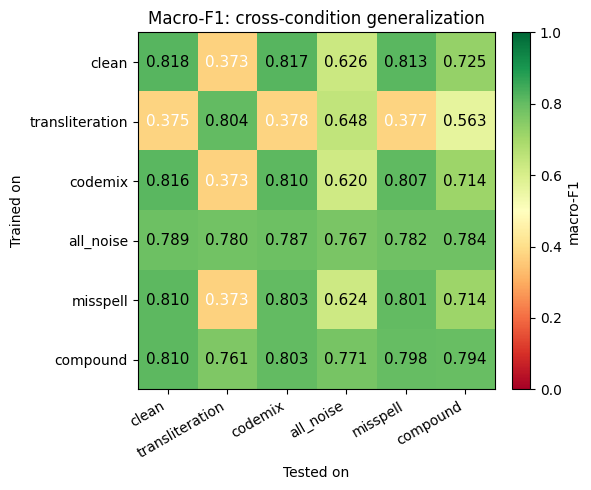

Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/crosscondition_macro_f1_matrix.csv


In [10]:
import matplotlib.pyplot as plt

pivot_f1 = results_df.pivot(index="train_condition", columns="test_condition", values="macro_f1")
pivot_f1 = pivot_f1.reindex(index=list(CONDITIONS.keys()), columns=list(CONDITIONS.keys()))
print(pivot_f1.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(pivot_f1.values, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot_f1.columns))); ax.set_xticklabels(pivot_f1.columns, rotation=30, ha="right")
ax.set_yticks(range(len(pivot_f1.index))); ax.set_yticklabels(pivot_f1.index)
ax.set_xlabel("Tested on"); ax.set_ylabel("Trained on")
ax.set_title("Macro-F1: cross-condition generalization")
for i in range(pivot_f1.shape[0]):
    for j in range(pivot_f1.shape[1]):
        val = pivot_f1.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                 color="white" if val < 0.5 else "black", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="macro-F1")
plt.tight_layout()
heatmap_path = os.path.join(RESULTS_DIR, "crosscondition_macro_f1_heatmap.png")
plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {heatmap_path}")
plt.show()

pivot_path = os.path.join(RESULTS_DIR, "crosscondition_macro_f1_matrix.csv")
pivot_f1.to_csv(pivot_path)
print(f"Saved -> {pivot_path}")


## 10. Majority-class baselines (per test condition, for reference)

Computed once per test condition's actual label distribution -- a property of the data, not of
any particular trained model -- so every row/column of the matrix above can be compared against
the same reference floor.


In [11]:
baseline_rows = []
for test_cond in CONDITIONS:
    test_df = data[test_cond]["test"]
    y_true = test_df["label"].values
    dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
    dummy.fit(np.zeros((len(y_true), 1)), y_true)
    y_dummy = dummy.predict(np.zeros((len(y_true), 1)))
    baseline_rows.append({"test_condition": test_cond,
                           "majority_baseline_macro_f1": f1_score(y_true, y_dummy, average="macro")})

baseline_df = pd.DataFrame(baseline_rows)
print(baseline_df)
baseline_path = os.path.join(RESULTS_DIR, "majority_baselines.csv")
baseline_df.to_csv(baseline_path, index=False)
print(f"Saved -> {baseline_path}")


    test_condition  majority_baseline_macro_f1
0            clean                    0.372647
1  transliteration                    0.372647
2          codemix                    0.372647
3        all_noise                    0.372647
4         misspell                    0.372647
5         compound                    0.372647
Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/majority_baselines.csv


## 11. Vocabulary-mismatch (OOV) matrix

For each (train condition, test condition) pair: what fraction of the test text's character
n-grams are unseen by the vocabulary the training model actually learned? This helps explain *why*
cross-condition macro-F1 drops -- if a model trained on clean text sees a much higher OOV rate on
transliterated test text than on its own clean test text, that's direct evidence of vocabulary
mismatch driving the performance gap.


test_condition    clean  transliteration  codemix  all_noise  misspell  \
train_condition                                                          
clean            0.0818           0.3124   0.0977     0.2177    0.1021   
transliteration  0.7850           0.0348   0.7099     0.3784    0.7864   
codemix          0.0878           0.2781   0.0842     0.1892    0.1078   
all_noise        0.1215           0.0646   0.1106     0.0993    0.1365   
misspell         0.0841           0.3150   0.1003     0.2164    0.0978   
compound         0.1004           0.0782   0.0992     0.1054    0.1179   

test_condition   compound  
train_condition            
clean              0.1621  
transliteration    0.5378  
codemix            0.1488  
all_noise          0.1062  
misspell           0.1623  
compound           0.1000  
Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/crosscondition_oov_heatmap.png


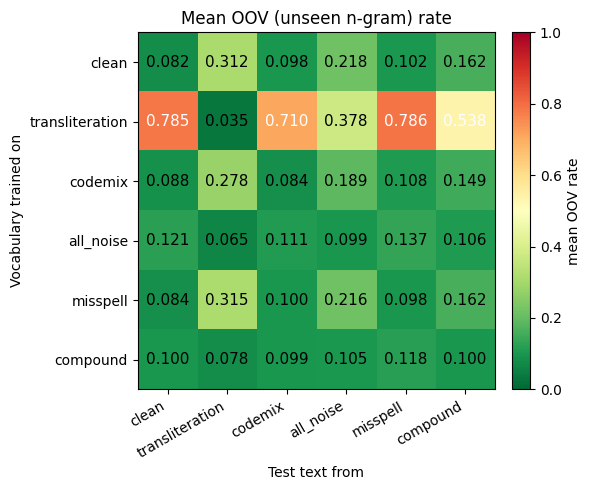

Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/crosscondition_oov_matrix.csv


In [12]:
oov_rows = []
for train_cond, art in all_artifacts.items():
    char_vec = art["pipeline"].named_steps["features"].transformer_list[0][1]  # ("char_tfidf", vec)
    vocab = set(char_vec.vocabulary_.keys())
    analyzer = char_vec.build_analyzer()

    def oov_rate(text, vocab=vocab, analyzer=analyzer):
        grams = analyzer(text)
        if not grams:
            return 0.0
        return sum(1 for g in grams if g not in vocab) / len(grams)

    for test_cond in CONDITIONS:
        test_df = data[test_cond]["test"]
        rates = test_df["model_text"].apply(oov_rate)
        oov_rows.append({"train_condition": train_cond, "test_condition": test_cond,
                          "mean_oov_rate": rates.mean()})

oov_df = pd.DataFrame(oov_rows)
oov_pivot = oov_df.pivot(index="train_condition", columns="test_condition", values="mean_oov_rate")
oov_pivot = oov_pivot.reindex(index=list(CONDITIONS.keys()), columns=list(CONDITIONS.keys()))
print(oov_pivot.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(oov_pivot.values, cmap="RdYlGn_r", vmin=0, vmax=1)
ax.set_xticks(range(len(oov_pivot.columns))); ax.set_xticklabels(oov_pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(len(oov_pivot.index))); ax.set_yticklabels(oov_pivot.index)
ax.set_xlabel("Test text from"); ax.set_ylabel("Vocabulary trained on")
ax.set_title("Mean OOV (unseen n-gram) rate")
for i in range(oov_pivot.shape[0]):
    for j in range(oov_pivot.shape[1]):
        val = oov_pivot.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                 color="white" if val > 0.5 else "black", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="mean OOV rate")
plt.tight_layout()
oov_heatmap_path = os.path.join(RESULTS_DIR, "crosscondition_oov_heatmap.png")
plt.savefig(oov_heatmap_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {oov_heatmap_path}")
plt.show()

oov_pivot.to_csv(os.path.join(RESULTS_DIR, "crosscondition_oov_matrix.csv"))
print(f"Saved -> {os.path.join(RESULTS_DIR, 'crosscondition_oov_matrix.csv')}")


## 12. Confusion matrices (own-condition diagonal)

Saved -> /content/drive/MyDrive/data/results/xgboost_crosscondition/own_condition_confusion_matrices.png


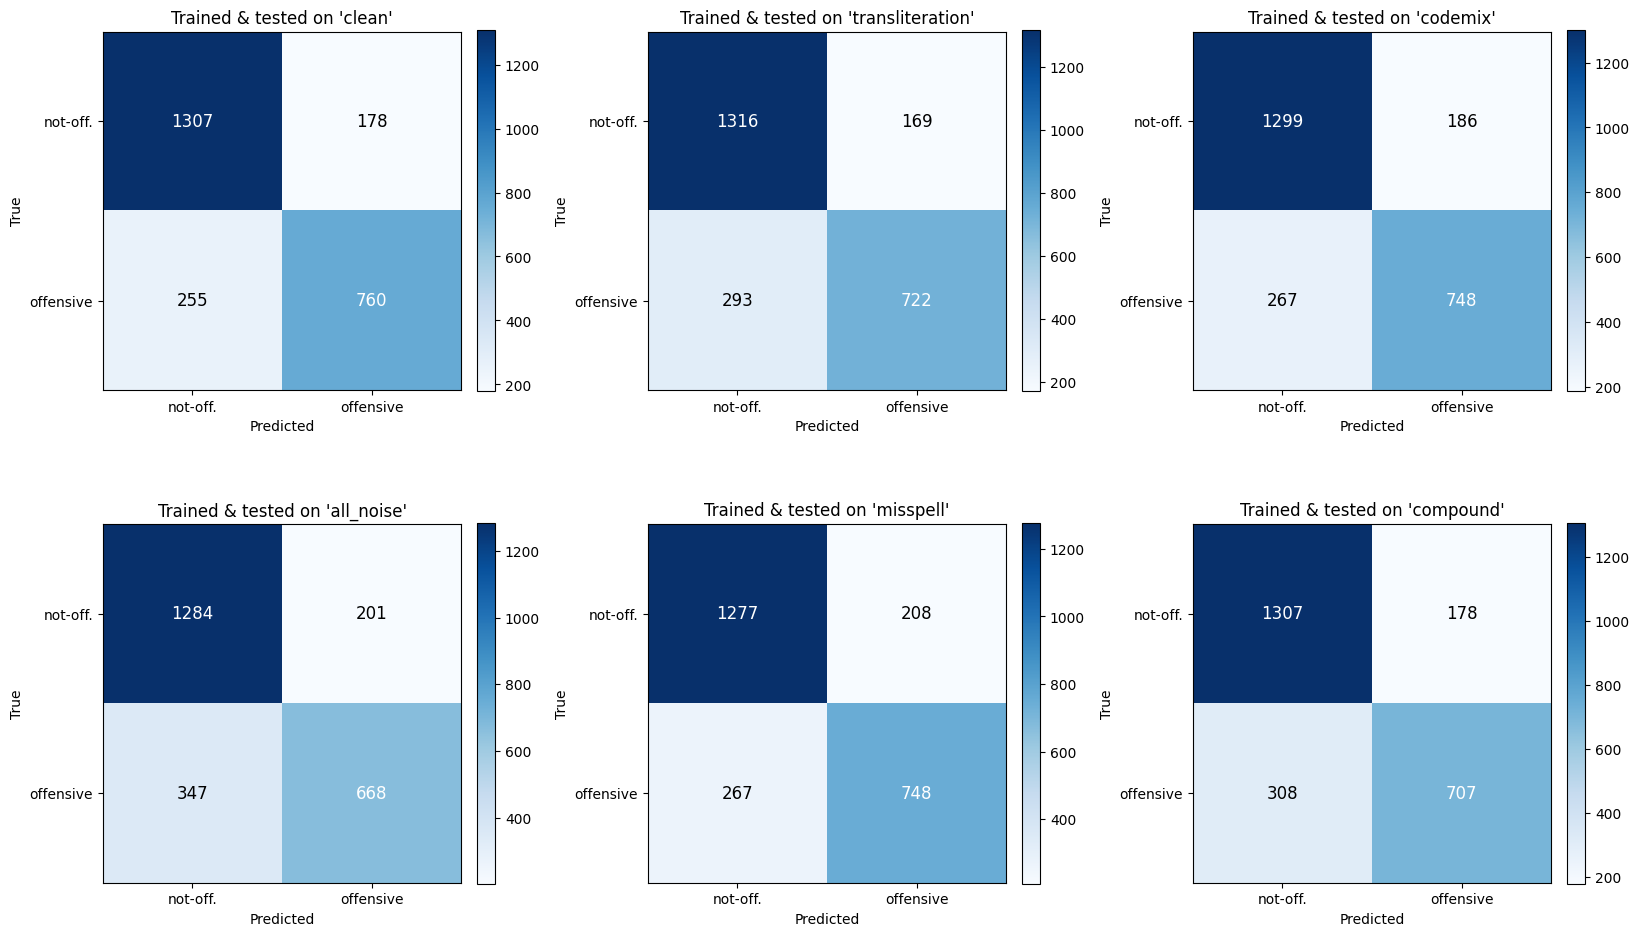

In [13]:
import math

n_cond = len(CONDITIONS)
n_cols = 3
n_rows = math.ceil(n_cond / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 5 * n_rows))
axes = np.array(axes).reshape(-1)  # flatten regardless of shape

for ax, cond in zip(axes, CONDITIONS):
    cm = all_cms[(cond, cond)]
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Trained & tested on '{cond}'")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["not-off.", "offensive"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["not-off.", "offensive"])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# hide any unused subplots (when n_cond isn't a multiple of n_cols)
for ax in axes[n_cond:]:
    ax.axis("off")

plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "own_condition_confusion_matrices.png")
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {cm_path}")
plt.show()


## 13. Feature importance per trained model


Top 20 features -- model trained on 'clean':


,feature,importance
0,char_tfidf__නොදක,0.010880
1,char_tfidf__ පුක,0.009271
2,char_tfidf__්කිල,0.006260
3,char_tfidf__ හු,0.005694
4,char_tfidf__ොන්,0.005635
5,char_tfidf__පුක,0.004453
6,char_tfidf__ජ්ජ,0.004197
7,char_tfidf__හැත,0.004020
8,char_tfidf__ොදකි,0.004017
9,char_tfidf__සක්ක,0.004016


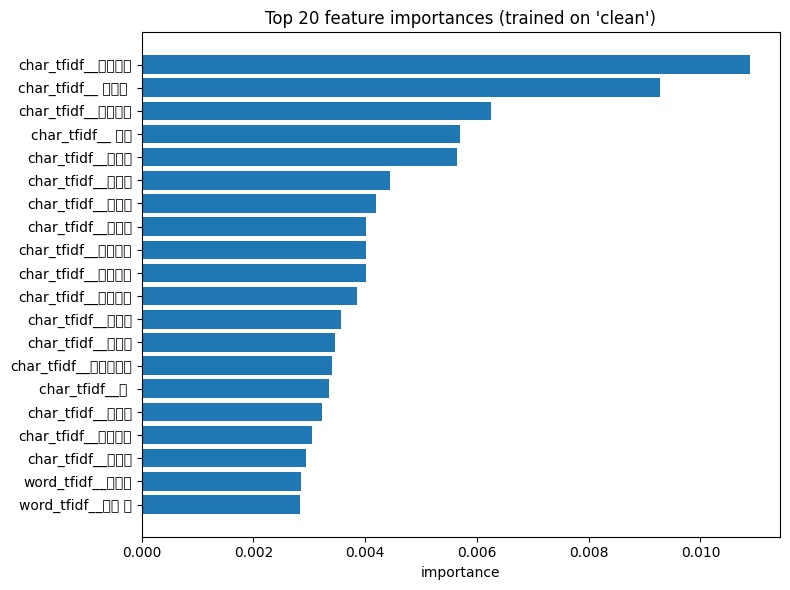


Top 20 features -- model trained on 'transliteration':


,feature,importance
0,char_tfidf__puka,0.007991
1,char_tfidf__akkil,0.006720
2,char_tfidf__ hu,0.006141
3,char_tfidf__ ponn,0.006126
4,char_tfidf__kkil,0.005379
5,char_tfidf__puk,0.004905
6,char_tfidf__ajath,0.004645
7,char_tfidf__kalak,0.004172
8,char_tfidf__sakk,0.003690
9,char_tfidf__daki,0.003680


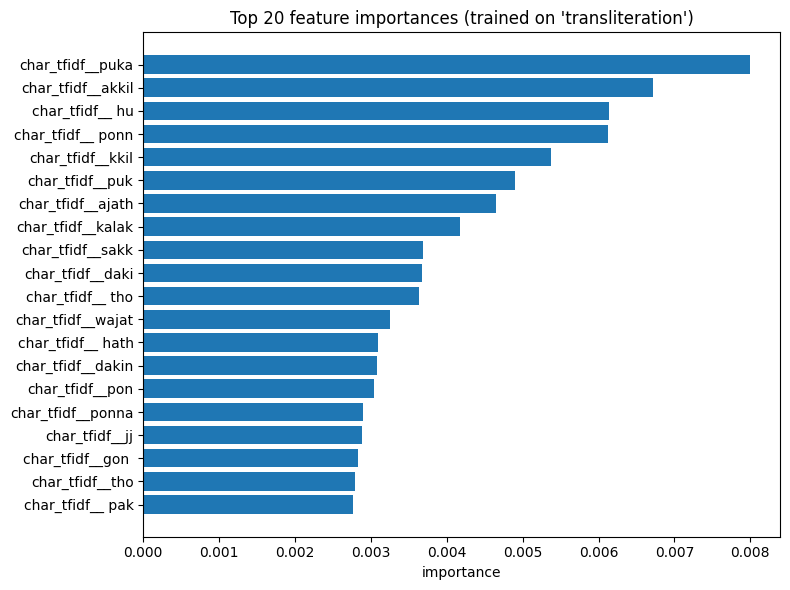


Top 20 features -- model trained on 'codemix':


,feature,importance
0,char_tfidf__ොන්,0.006408
1,char_tfidf__ හු,0.006271
2,char_tfidf__පුක,0.005784
3,char_tfidf__සක්ක,0.004953
4,char_tfidf__නොදකි,0.004382
5,char_tfidf__හැත,0.004358
6,char_tfidf__නොදක,0.004055
7,word_tfidf__අවජ තක,0.003938
8,char_tfidf__ හැත,0.003891
9,char_tfidf__වේස,0.003864


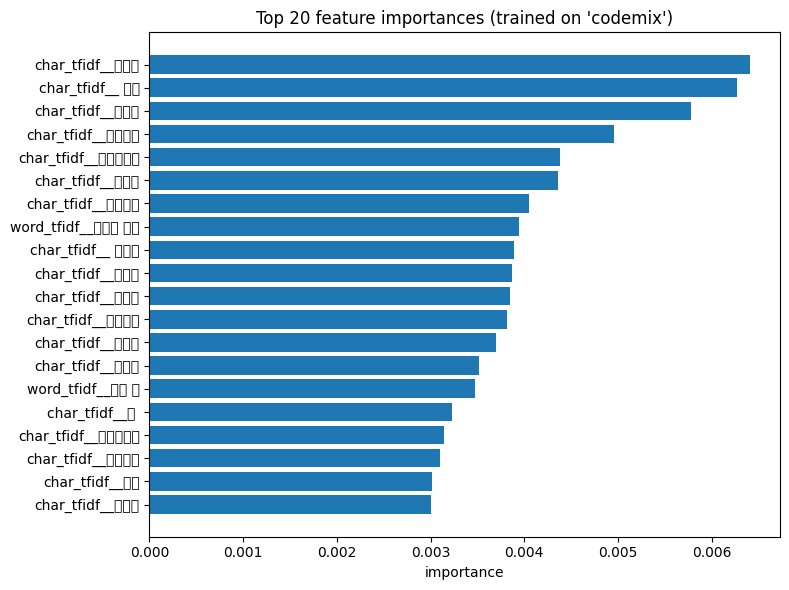


Top 20 features -- model trained on 'all_noise':


,feature,importance
0,char_tfidf__alaka,0.004303
1,char_tfidf__ොන්,0.003072
2,char_tfidf__ හු,0.002898
3,char_tfidf__ pon,0.002796
4,char_tfidf__ hu,0.002536
5,char_tfidf__daki,0.002440
6,char_tfidf__ තො,0.002198
7,char_tfidf__ ponn,0.002160
8,char_tfidf__දකි,0.002158
9,char_tfidf__akann,0.002142


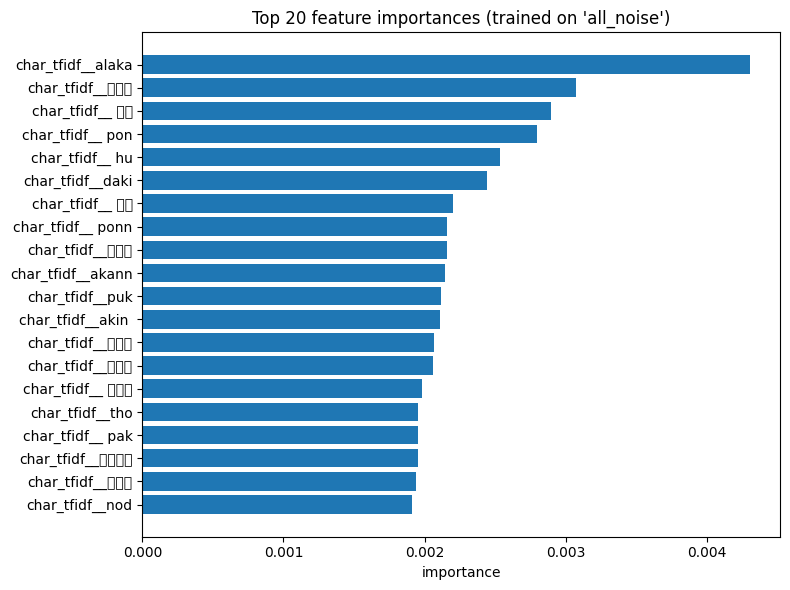


Top 20 features -- model trained on 'misspell':


,feature,importance
0,char_tfidf__පුක,0.006241
1,char_tfidf__ොන්,0.006081
2,char_tfidf__ හු,0.006008
3,char_tfidf__හැත,0.005336
4,char_tfidf__ජ්ජ,0.004998
5,char_tfidf__කාලක,0.004984
6,char_tfidf__ොදකි,0.004710
7,char_tfidf__වේස,0.004276
8,char_tfidf__ තො,0.004172
9,char_tfidf__්කිලි,0.004167


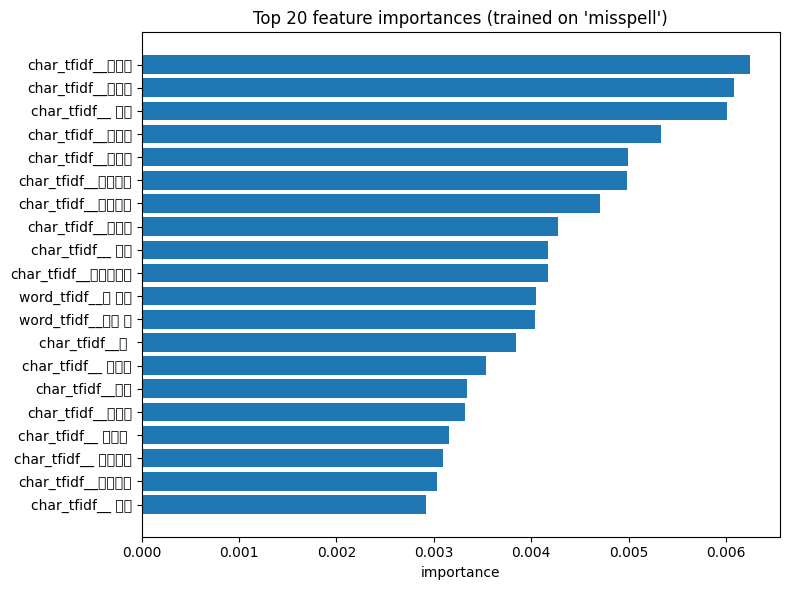


Top 20 features -- model trained on 'compound':


,feature,importance
0,char_tfidf__ොදක,0.005879
1,char_tfidf__්කිලි,0.005574
2,char_tfidf__ හු,0.003867
3,char_tfidf__සක්ක,0.003787
4,char_tfidf__ොන්,0.003536
5,word_tfidf__ජ ජ,0.003414
6,char_tfidf__ කාලක,0.003367
7,char_tfidf__හැත,0.003320
8,char_tfidf__පුක,0.003262
9,char_tfidf__දකින්,0.003081


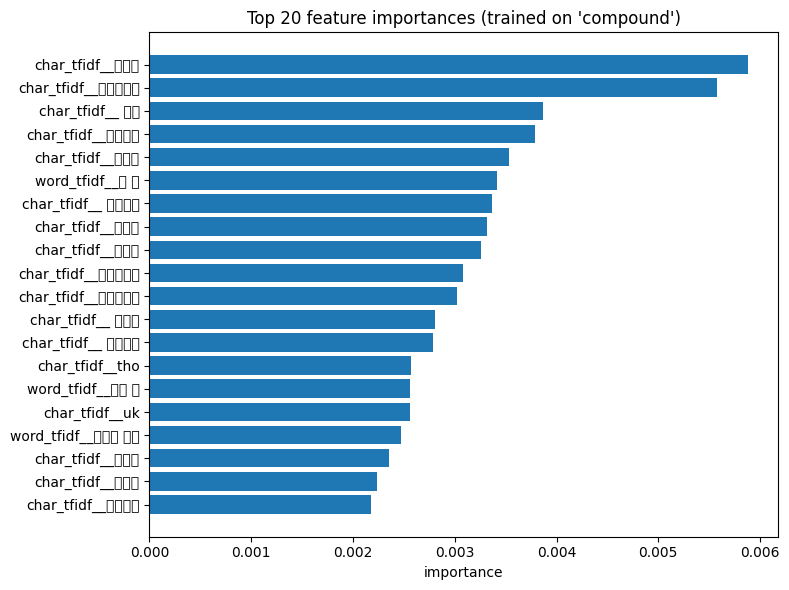

In [14]:
def show_top_features(cond, top_n=20):
    pipeline = all_artifacts[cond]["pipeline"]
    feature_union = pipeline.named_steps["features"]
    model = pipeline.named_steps["clf"]

    all_names = feature_union.get_feature_names_out()
    importances = model.feature_importances_
    order = np.argsort(importances)[::-1][:top_n]

    top_feats = pd.DataFrame({"feature": all_names[order], "importance": importances[order]})
    print(f"\nTop {top_n} features -- model trained on '{cond}':")
    display(top_feats)

    plt.figure(figsize=(8, 6))
    plt.barh(top_feats["feature"][::-1], top_feats["importance"][::-1])
    plt.title(f"Top {top_n} feature importances (trained on '{cond}')")
    plt.xlabel("importance")
    plt.tight_layout()
    fi_path = os.path.join(RESULTS_DIR, f"feature_importance_trained_on_{cond}.png")
    plt.savefig(fi_path, dpi=150, bbox_inches="tight")
    plt.show()

    top_feats.to_csv(os.path.join(RESULTS_DIR, f"feature_importance_trained_on_{cond}.csv"), index=False)

for cond in CONDITIONS:
    show_top_features(cond)


## Summary

- **Section 7** trained 6 independent models, one per condition (clean, transliteration, codemix,
  all_noise, misspell, compound), each seeing only its own training data.
- **Section 8/9** produced the full 6x6 macro-F1 generalization matrix and heatmap — the main
  result for this experiment. The diagonal is your "own-condition" performance (comparable to the
  single-condition notebooks); off-diagonal cells show cross-condition generalization gaps.
- **Section 11** gives a mechanistic explanation for any generalization gap you see: vocabulary
  mismatch between what a model learned and what it's being tested on.
- All models, matrices, and plots are saved under `RESULTS_DIR` in your Drive.
- **To add a new condition:** edit only the `CONDITIONS` dictionary in Section 3 — every other
  section already loops over `CONDITIONS` generically and needs no further changes.
